# Analisis Backtest MTF Trend Following (1D) & Price Action Pullback (1H)

Dokumen ini memuat implementasi strategi kuantitatif Multi-Timeframe (MTF) murni berbasis **Trend Following (1D)** dan **Price Action Pullback (1H)** tanpa osilator CCI. Sistem dievaluasi menggunakan metode *Continuous Run* melintasi berbagai fase pasar, tanpa reset nilai ekuitas antar jendela analisis.

Arsitektur Sinyal & Mitigasi Overfitting:
1. **Parameter Konfigurasi Universal**: Seluruh instrumen diuji menggunakan konfigurasi parameter seragam (`GLOBAL_PARAMS`) tanpa kurva *curve-fitting* atau *override* lokal per simbol.
2. **Sanitasi Jam Bursa Reguler (RTH)**: Data 1H disaring hanya pada jam bursa reguler (09:00 - 16:00 waktu bursa) untuk mengeliminasi celah likuiditas rendah malam hari.
3. **Pencegahan Lookahead Bias**: Seluruh indikator makro 1D (`ema_macro_fast`, `ema_macro_slow`) digeser satu bar (`.shift(1)`) sebelum digabungkan (*forward-fill*) ke data 1H.
4. **Dimensi Makro (1D)**: Menentukan izin arah tren utama (`macro_bullish = Fast > Slow`, `macro_bearish = Fast < Slow`).
5. **Dimensi Mikro (1H)**: Menggunakan `ema_micro` (20) sebagai acuan nilai wajar dan `atr` (14) pada data 1H untuk trailing stop adaptif.
6. **Price Action Pullback**:
   - **Entry Long**: Izin makro bullish aktif, bar sebelumnya pullback menyentuh nilai wajar (`Low[i-1] <= EMA_micro[i-1]`), bar saat ini rebound di atas nilai wajar (`Close[i] > EMA_micro[i]`), serta jeda `bars_since_exit >= cooldown_bars`.
   - **Entry Short**: Izin makro bearish aktif, bar sebelumnya pullback naik (`High[i-1] >= EMA_micro[i-1]`), bar saat ini penolakan ke bawah (`Close[i] < EMA_micro[i]`), serta jeda `bars_since_exit >= cooldown_bars`.
7. **Manajemen Risiko Asimetris**: Trailing Stop diperbarui secara dinamis (`atr_mult_long = 3.0`, `atr_mult_short = 2.0`) dengan exit darurat jika tren makro 1D resmi patah.


In [309]:
# =============================================================================
# KONFIGURASI GLOBAL & PARAMETER UNIVERSAL
# =============================================================================
CONFIG = {
    # --- Sumber data ---------------------------------------------------------
    'data_dir': 'data_index',
    'instruments': {
        'SPY':  {'nama': 'S&P 500 (SPY)',    'file_1d': 'spy_US500_D1.parquet',
                 'file_1h': 'spy_US500_H1.parquet', 'warna': 'blue'},
        'QQQ':  {'nama': 'NASDAQ 100 (QQQ)', 'file_1d': 'Nasdaq100_1d_data.csv',
                 'file_1h': 'Nasdaq100_1h_data.csv', 'warna': 'green'},
        'DJI':  {'nama': 'DOW JONES (DJI)',  'file_1d': 'Dow_Jones_1d_data.csv',
                 'file_1h': 'Dow_Jones_1h_data.csv', 'warna': 'purple'},
        'AAPL': {'nama': 'APPLE INC. (AAPL)', 'file_1d': 'validasi-aapl/aapl_1d.csv',
                 'file_1h': 'validasi-aapl/aapl_1h.csv', 'warna': 'darkorange'},
    },

    # --- Pra-pemrosesan data -------------------------------------------------
    'sinkronisasi_rentang': True,   # potong ke irisan waktu bersama semua instrumen
    'hapus_akhir_pekan': True,      # buang baris Sabtu/Minggu (artefak resampling 24/7)
    'filter_rth': True,             # hanya simpan jam bursa reguler (09:00 - 16:00)

    # --- Sistem modal & biaya ------------------------------------------------
    'initial_capital': 1000.0,
    'fee': 0.0003,                  # komisi 0.02% + slippage 0.01% per sisi transaksi

    # --- Pelaporan -----------------------------------------------------------
    'trading_days_per_year': 252,
    'fase_pasar': {
        'urutan': ['Bullish', 'Bearish', 'Sideways'],
        'default': 'Sideways',
        'label_keseluruhan': 'Keseluruhan Berjalan',
    },
    'log_tail': 5,                  # jumlah transaksi terakhir yang dicetak
}

GLOBAL_PARAMS = {
    'ema_macro_fast': 20,       # EMA 1D untuk arah tren utama
    'ema_macro_slow': 50,       # EMA 1D jangkar tren utama
    'ema_micro': 32,            # EMA 1H sebagai level harga wajar (pullback target)
    'atr_period': 7,           # ATR 1H untuk trailing stop adaptif
    'atr_mult_long': 5.0,       # Toleransi trailing stop Long
    'atr_mult_short': 2.0,      # Toleransi trailing stop Short (lebih ketat)
    'cooldown_bars': 6,        # Jeda bar 1H setelah posisi ditutup
    'enable_short': True        # Aktifkan dua arah untuk semua instrumen
}

print("Konfigurasi global & parameter universal dimuat:", list(CONFIG['instruments'].keys()))


Konfigurasi global & parameter universal dimuat: ['SPY', 'QQQ', 'DJI', 'AAPL']


In [310]:
# =============================================================================
# BLOK 1: PERSIAPAN & LOAD LIBRARY
# =============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
print("Modul dasar berhasil dimuat.")


Modul dasar berhasil dimuat.


In [311]:
# =============================================================================
# BLOK 2: INGESTI, PEMBERSIHAN, & SINKRONISASI RENTANG WAKTU (1D dan 1H RTH)
# =============================================================================
import os

def load_and_clean_data(file_path):
    if file_path.endswith('.parquet'):
        df = pd.read_parquet(file_path)
    else:
        with open(file_path) as f:
            sep = '\t' if '\t' in f.readline() else ','
        df = pd.read_csv(file_path, sep=sep)

    df.columns = [c.lower() for c in df.columns]

    if 'datetime' in df.columns:
        df['datetime'] = pd.to_datetime(df['datetime'])
    elif 'date' in df.columns:
        df['datetime'] = pd.to_datetime(df['date'])
        df.drop(columns=['date'], inplace=True, errors='ignore')
    elif 'time' in df.columns:
        df['datetime'] = pd.to_datetime(df['time'])

    df.sort_values('datetime', inplace=True)
    df.set_index('datetime', inplace=True)

    if CONFIG['hapus_akhir_pekan']:
        df = df[df.index.dayofweek < 5]

    df['date'] = df.index.date
    return df

def muat_semua_data(config):
    data = {}
    for kode, meta in config['instruments'].items():
        df_1d = load_and_clean_data(os.path.join(config['data_dir'], meta['file_1d']))
        df_1h = load_and_clean_data(os.path.join(config['data_dir'], meta['file_1h']))
        
        # Filter Jam Bursa Reguler / RTH (09:00 - 16:00 waktu bursa)
        if config.get('filter_rth', True):
            df_1h = df_1h[(df_1h.index.hour >= 9) & (df_1h.index.hour <= 16)]
            
        data[kode] = {'1d': df_1d, '1h': df_1h}
    return data

def hitung_rentang_bersama(data):
    # Start = MAX tanggal awal; End = MIN tanggal akhir (seluruh instrumen, 1D & 1H)
    awal = [df.index[0].normalize() for d in data.values() for df in d.values()]
    akhir = [df.index[-1].normalize() for d in data.values() for df in d.values()]
    start, end = max(awal), min(akhir)
    if start > end:
        raise ValueError(f"Tidak ada irisan waktu antar instrumen: {start} > {end}")
    return start, end

def potong_rentang(df, start, end):
    # End bersifat inklusif sampai akhir hari (23:59:59.999...)
    return df.loc[start: end + pd.Timedelta(days=1) - pd.Timedelta(nanoseconds=1)].copy()

try:
    DATA_MENTAH = muat_semua_data(CONFIG)

    if CONFIG['sinkronisasi_rentang']:
        START_BERSAMA, END_BERSAMA = hitung_rentang_bersama(DATA_MENTAH)
        DATA = {k: {tf: potong_rentang(df, START_BERSAMA, END_BERSAMA) for tf, df in d.items()}
                for k, d in DATA_MENTAH.items()}
    else:
        START_BERSAMA, END_BERSAMA = None, None
        DATA = DATA_MENTAH

    print("Data historis berhasil dimuat dan disanitasi (RTH 09:00-16:00).")
    if CONFIG['sinkronisasi_rentang']:
        print(f"Rentang waktu bersama: {START_BERSAMA.date()} s.d. {END_BERSAMA.date()}")
    print(f"{'Instrumen':<10}{'TF':<5}{'Baris (mentah)':>16}{'Baris (sinkron)':>17}  Rentang sinkron")
    for kode in DATA:
        for tf in ('1d', '1h'):
            raw, syn = DATA_MENTAH[kode][tf], DATA[kode][tf]
            print(f"{kode:<10}{tf.upper():<5}{len(raw):>16,}{len(syn):>17,}  "
                  f"{syn.index[0]} -> {syn.index[-1]}")
except Exception as e:
    print(f"Kesalahan saat memuat data: {e}")


Data historis berhasil dimuat dan disanitasi (RTH 09:00-16:00).
Rentang waktu bersama: 2018-02-19 s.d. 2024-05-10
Instrumen TF     Baris (mentah)  Baris (sinkron)  Rentang sinkron
SPY       1D              3,627            1,608  2018-02-19 00:00:00 -> 2024-05-10 00:00:00
SPY       1H             17,525           12,829  2018-02-19 16:00:00 -> 2024-05-10 16:00:00
QQQ       1D              2,283            1,600  2018-02-19 00:00:00 -> 2024-05-10 00:00:00
QQQ       1H             18,209           12,769  2018-02-19 09:00:00 -> 2024-05-10 16:00:00
DJI       1D              2,250            1,609  2018-02-19 00:00:00 -> 2024-05-10 00:00:00
DJI       1H             17,978           12,850  2018-02-19 09:00:00 -> 2024-05-10 16:00:00
AAPL      1D              4,384            1,485  2018-02-19 00:00:00 -> 2024-05-10 00:00:00
AAPL      1H             35,072           11,880  2018-02-19 09:00:00 -> 2024-05-10 16:00:00


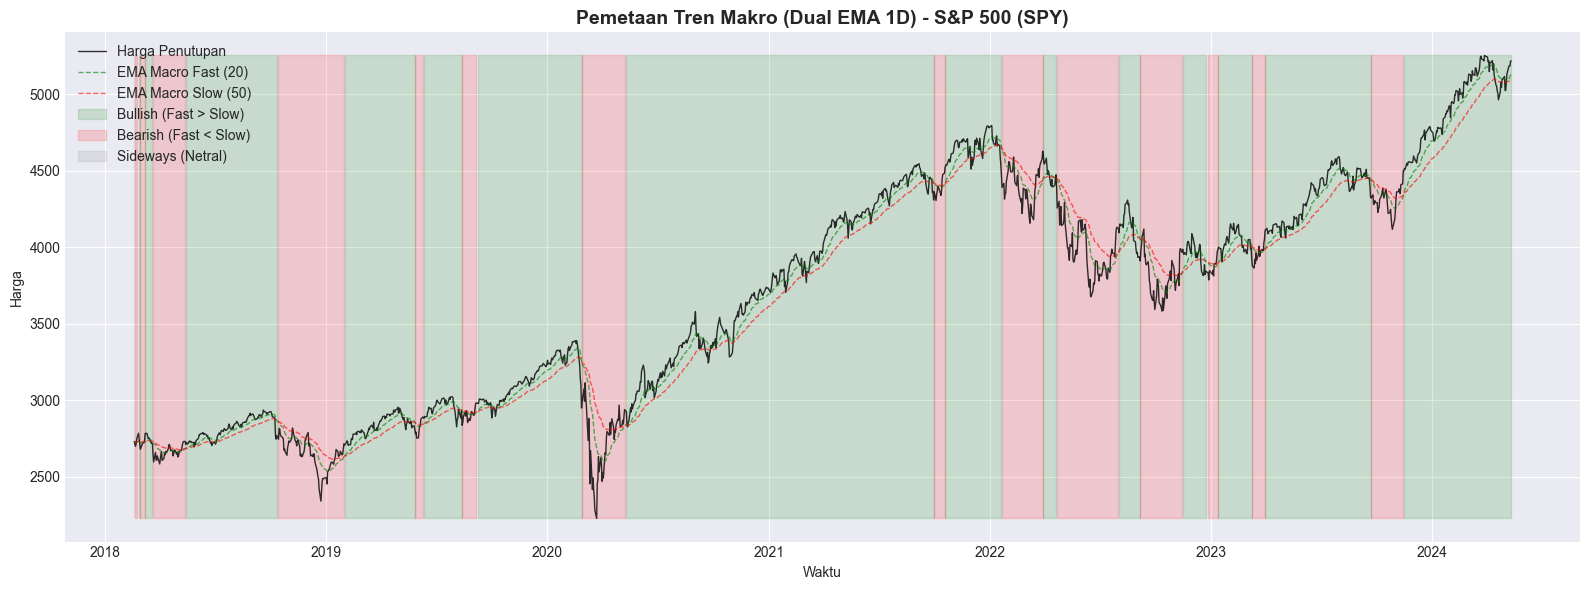

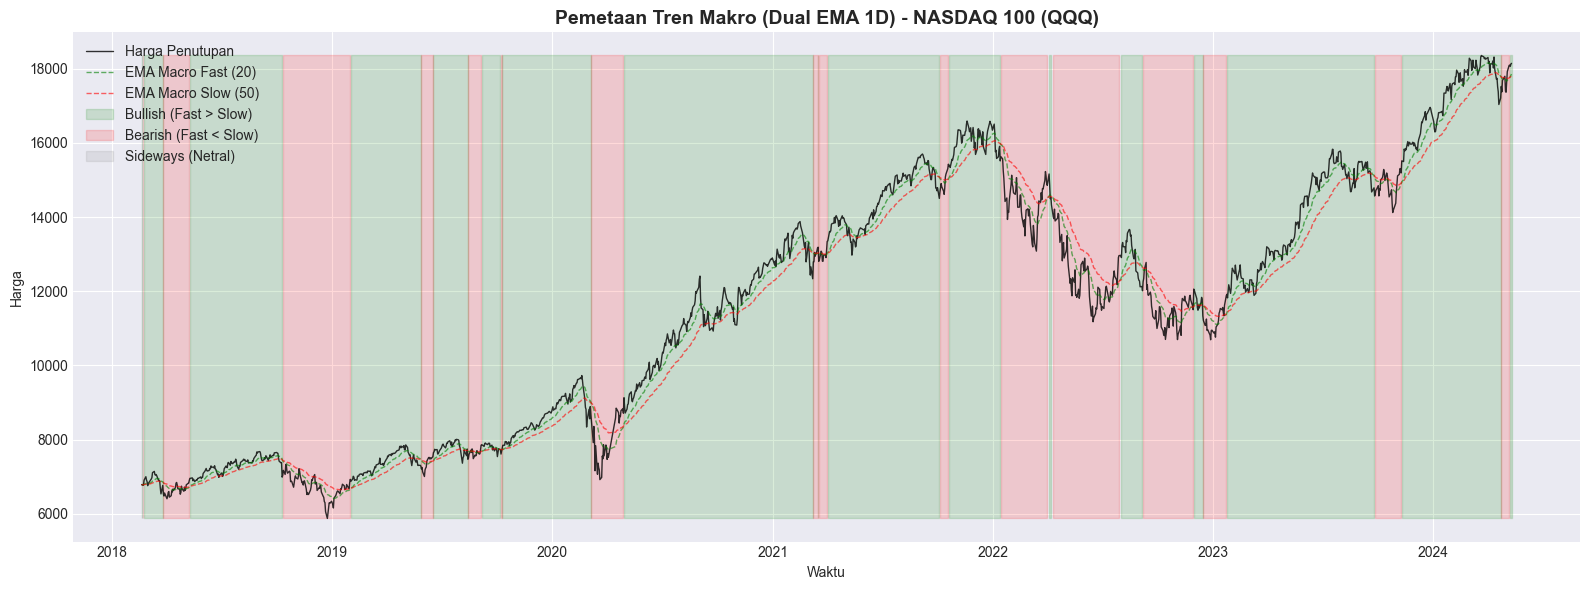

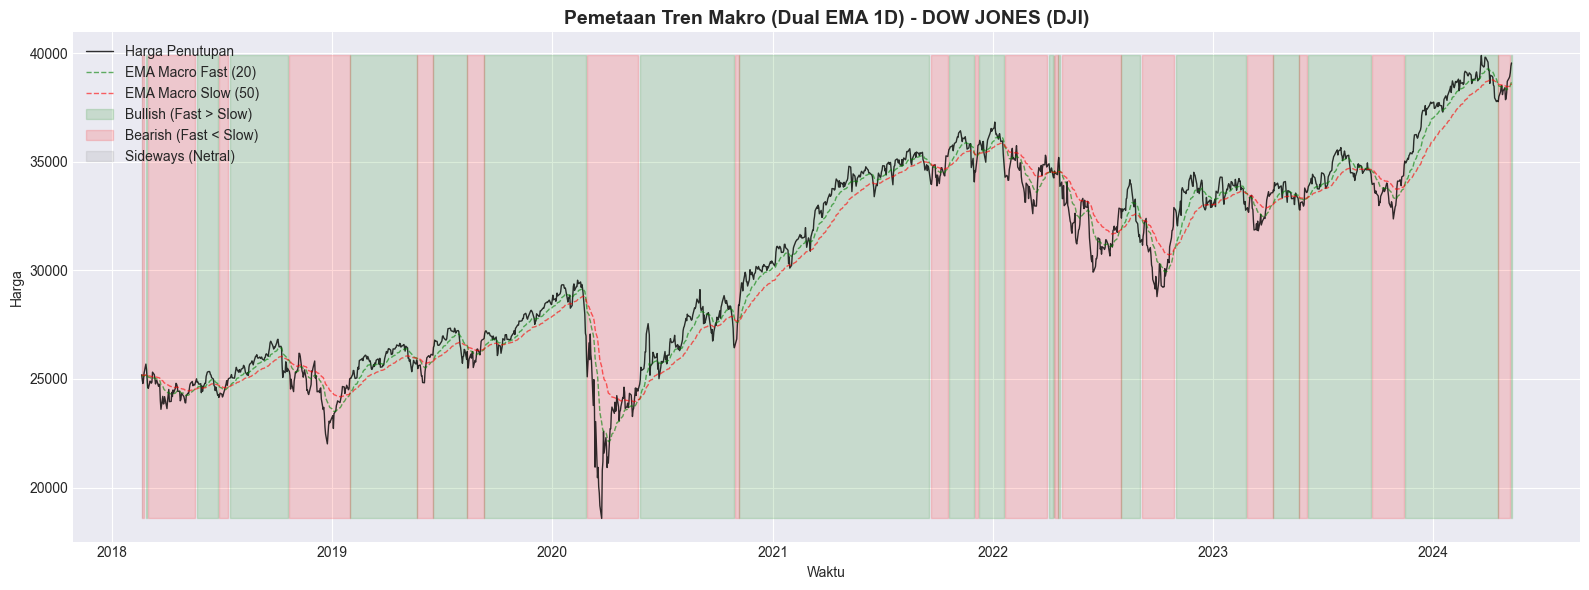

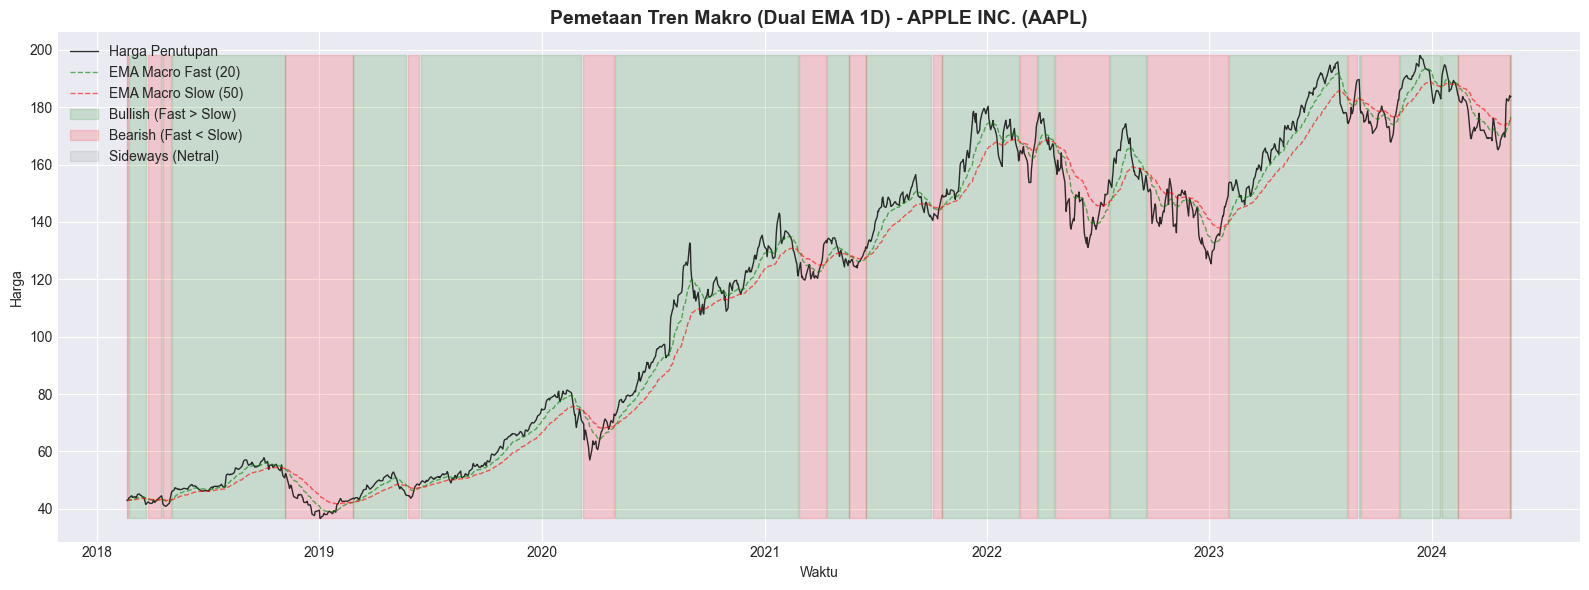

In [312]:
# =============================================================================
# BLOK 3: VISUALISASI EKSPLORATIF (PEMETAAN TREN MAKRO DUAL EMA 1D)
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def calc_ema_lokal(series, span):
    return series.ewm(span=span, adjust=False).mean()

def tentukan_fase_pasar(ema_fast, ema_slow):
    cfg = CONFIG['fase_pasar']
    bullish, bearish, sideways = cfg['urutan']
    fase = pd.Series(sideways, index=ema_fast.index, dtype=object)
    fase[ema_fast > ema_slow] = bullish
    fase[ema_fast < ema_slow] = bearish
    return fase

def plot_fase_pasar(df_1d, nama_instrumen, params=None):
    params = GLOBAL_PARAMS if params is None else params
    df_plot = df_1d.copy()
    bullish, bearish, sideways = CONFIG['fase_pasar']['urutan']

    df_plot['ema_fast'] = calc_ema_lokal(df_plot['close'], params['ema_macro_fast'])
    df_plot['ema_slow'] = calc_ema_lokal(df_plot['close'], params['ema_macro_slow'])
    df_plot['fase_pasar'] = tentukan_fase_pasar(df_plot['ema_fast'], df_plot['ema_slow'])

    y_min, y_max = df_plot['close'].min(), df_plot['close'].max()
    plt.figure(figsize=(16, 6))
    plt.plot(df_plot.index, df_plot['close'], color='black', linewidth=1, alpha=0.8, label='Harga Penutupan')
    plt.plot(df_plot.index, df_plot['ema_fast'], color='green', linewidth=1, linestyle='--', alpha=0.6, label=f"EMA Macro Fast ({params['ema_macro_fast']})")
    plt.plot(df_plot.index, df_plot['ema_slow'], color='red', linewidth=1, linestyle='--', alpha=0.6, label=f"EMA Macro Slow ({params['ema_macro_slow']})")

    for fase, warna, label in [(bullish, 'green', f'{bullish} (Fast > Slow)'),
                               (bearish, 'red', f'{bearish} (Fast < Slow)'),
                               (sideways, 'gray', f'{sideways} (Netral)')]:
        plt.fill_between(df_plot.index, y_min, y_max, where=(df_plot['fase_pasar'] == fase),
                         color=warna, alpha=0.15, label=label)

    plt.title(f"Pemetaan Tren Makro (Dual EMA 1D) - {nama_instrumen}", fontsize=14, fontweight='bold')
    plt.ylabel("Harga")
    plt.xlabel("Waktu")

    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys(), loc='upper left')
    plt.tight_layout()
    plt.show()

if 'DATA' in locals():
    for kode, meta in CONFIG['instruments'].items():
        plot_fase_pasar(DATA[kode]['1d'], meta['nama'])


In [313]:
# =============================================================================
# BLOK 4: MODUL INDIKATOR TEKNIKAL (EMA, ATR)
# =============================================================================
def calc_ema(series, span):
    return series.ewm(span=span, adjust=False).mean()

def calc_atr(df, period):
    close_prev = df['close'].shift(1)
    tr = pd.concat([df['high'] - df['low'],
                    (df['high'] - close_prev).abs(),
                    (df['low'] - close_prev).abs()], axis=1).max(axis=1)
    return calc_ema(tr, period)

print("Modul indikator (EMA, ATR) berhasil didefinisikan.")


Modul indikator (EMA, ATR) berhasil didefinisikan.


In [314]:
# =============================================================================
# BLOK 5: MESIN INTI (CORE ENGINE) - STATE MACHINE PULLBACK & PRICE ACTION
# =============================================================================

def run_backtest(df_1d, df_1h, symbol, initial_capital=None, fee=None, params=None):
    p = GLOBAL_PARAMS if params is None else params
    capital = CONFIG['initial_capital'] if initial_capital is None else initial_capital
    fee = CONFIG['fee'] if fee is None else fee

    # 1. Indikator makro (1D), digeser 1 bar untuk mencegah lookahead bias
    d1 = df_1d.copy()
    d1['ema_macro_fast'] = calc_ema(d1['close'], p['ema_macro_fast']).shift(1)
    d1['ema_macro_slow'] = calc_ema(d1['close'], p['ema_macro_slow']).shift(1)
    d1['macro_bullish'] = d1['ema_macro_fast'] > d1['ema_macro_slow']
    d1['macro_bearish'] = d1['ema_macro_fast'] < d1['ema_macro_slow']
    d1['fase_pasar'] = tentukan_fase_pasar(d1['ema_macro_fast'], d1['ema_macro_slow'])

    # 2. Penggabungan ke data 1H berdasarkan tanggal
    d1_sub = d1[['date', 'ema_macro_fast', 'ema_macro_slow', 'macro_bullish', 'macro_bearish', 'fase_pasar']]
    df = pd.merge(df_1h.copy().reset_index(), d1_sub, on='date', how='left')
    df.ffill(inplace=True)
    df.set_index('datetime', inplace=True)

    # 3. Indikator mikro (1H)
    df['ema_micro'] = calc_ema(df['close'], p['ema_micro'])
    df['atr'] = calc_atr(df, p['atr_period'])
    df.dropna(inplace=True)

    close, high, low = df['close'].values, df['high'].values, df['low'].values
    ema_u = df['ema_micro'].values
    atr = df['atr'].values
    macro_bull = df['macro_bullish'].values
    macro_bear = df['macro_bearish'].values
    dates = df.index
    n = len(df)

    # 4. State machine: pos = 1 (Long), -1 (Short), 0 (Flat)
    pos = 0
    shares = cap_net = entry_px = stop = 0.0
    entry_dt = None
    bars_since_exit = float('inf')
    equity = np.full(n, capital, dtype=float)
    trades = []

    for i in range(1, n):
        # Kondisi Posisi FLAT (Posisi = 0)
        if pos == 0:
            bars_since_exit += 1
            if bars_since_exit >= p.get('cooldown_bars', 0):
                long_sig = macro_bull[i] and (low[i-1] <= ema_u[i-1]) and (close[i] > ema_u[i])
                short_sig = p.get('enable_short', True) and macro_bear[i] and (high[i-1] >= ema_u[i-1]) and (close[i] < ema_u[i])
                if long_sig or short_sig:
                    pos = 1 if long_sig else -1
                    entry_px, entry_dt = close[i], dates[i]
                    cap_net = capital * (1 - fee)
                    shares = cap_net / entry_px
                    if pos == 1:
                        stop = entry_px - p['atr_mult_long'] * atr[i]
                    else:
                        stop = entry_px + p['atr_mult_short'] * atr[i]
            equity[i] = capital
            continue

        # Kondisi Posisi AKTIF (Posisi = 1 atau Posisi = -1)
        exit_px, reason = None, None
        if pos == 1:
            # Perbarui Trailing Stop
            stop = max(stop, close[i] - p['atr_mult_long'] * atr[i])
            if low[i] <= stop:
                exit_px, reason = stop, 'Trailing Stop'
            elif not macro_bull[i]:
                exit_px, reason = close[i], 'Macro Trend Broken'
        else:
            # Perbarui Trailing Stop
            stop = min(stop, close[i] + p['atr_mult_short'] * atr[i])
            if high[i] >= stop:
                exit_px, reason = stop, 'Trailing Stop'
            elif not macro_bear[i]:
                exit_px, reason = close[i], 'Macro Trend Broken'

        if exit_px is not None:
            gross = shares * exit_px if pos == 1 else cap_net + shares * (entry_px - exit_px)
            capital = max(0.0, gross * (1 - fee))
            trades.append({
                'Symbol': symbol,
                'Side': 'Long' if pos == 1 else 'Short',
                'Entry_Date': entry_dt,
                'Entry_Price': entry_px,
                'Exit_Date': dates[i],
                'Exit_Price': exit_px,
                'Profit_Pct': (pos * (exit_px / entry_px - 1) - 2 * fee) * 100,
                'Duration_Days': (dates[i] - entry_dt).total_seconds() / 86400,
                'Exit_Reason': reason,
            })
            pos = 0
            bars_since_exit = 0
            equity[i] = capital
        else:
            if pos == 1:
                equity[i] = shares * close[i]
            else:
                equity[i] = max(0.0, cap_net + shares * (entry_px - close[i]))

    df['Equity_Strat'] = equity
    df['Equity_BH'] = (CONFIG['initial_capital'] if initial_capital is None else initial_capital) / close[0] * close
    return df, pd.DataFrame(trades)


# -----------------------------------------------------------------------------
# EVALUASI FASE PASAR (Strategi & B&H memakai fungsi metrik yang SAMA)
# -----------------------------------------------------------------------------
KOLOM_LAPORAN = ['Fase Pasar', 'Return(%)', 'CAGR(%)', 'Max DD(%)', 'Sharpe', 'Sortino',
                 'Win Rate(%)', 'R/R Ratio', 'Time(%)', 'Trades']

def _ekstrak_kurva(df_sub, kol_ekuitas, kol_ret, keseluruhan):
    if keseluruhan:
        eq = df_sub[kol_ekuitas]
        total = eq.iloc[-1] / eq.iloc[0] - 1
        daily = eq.resample('D').last().dropna().pct_change().dropna()
    else:
        eq = (1 + df_sub[kol_ret]).cumprod()
        total = eq.iloc[-1] - 1
        daily = df_sub[kol_ret].resample('D').sum()
        daily = daily[daily != 0]
    return eq, daily, total

def _hitung_metrik(eq, daily, total_ret, n_days):
    ppy = CONFIG['trading_days_per_year']
    cagr = ((1 + total_ret) ** (ppy / n_days)) - 1 if total_ret > -1 else -1.0
    peak = eq.cummax()
    max_dd = ((eq - peak) / peak).min() * 100
    std = daily.std()
    sharpe = (daily.mean() / std) * np.sqrt(ppy) if len(daily) > 1 and std > 0 else 0.0
    downside_std = daily[daily < 0].std()
    sortino = (daily.mean() / downside_std) * np.sqrt(ppy) if len(daily[daily < 0]) > 1 and downside_std > 0 else 0.0
    return {'Return(%)': total_ret * 100, 'CAGR(%)': cagr * 100, 'Max DD(%)': max_dd,
            'Sharpe': sharpe, 'Sortino': sortino}

def _baris_laporan(fase, m, win_rate, rr, time_pct, trades):
    f = lambda x: x if isinstance(x, str) else f"{x:.2f}"
    return {'Fase Pasar': fase, 'Return(%)': f(m['Return(%)']), 'CAGR(%)': f(m['CAGR(%)']),
            'Max DD(%)': f(m['Max DD(%)']), 'Sharpe': f(m['Sharpe']), 'Sortino': f(m['Sortino']),
            'Win Rate(%)': f(win_rate), 'R/R Ratio': f(rr), 'Time(%)': f(time_pct), 'Trades': str(trades)}

def evaluasi_fase_pasar(df_merged, trade_log, symbol_name=""):
    df_merged = df_merged.copy()
    df_merged['strat_ret'] = df_merged['Equity_Strat'].pct_change().fillna(0)
    df_merged['bh_ret'] = df_merged['Equity_BH'].pct_change().fillna(0)

    label_all = CONFIG['fase_pasar']['label_keseluruhan']
    fase_list = [label_all] + CONFIG['fase_pasar']['urutan']
    nol = {k: 0.0 for k in ['Return(%)', 'CAGR(%)', 'Max DD(%)', 'Sharpe', 'Sortino']}
    strat_rows, bh_rows = [], []

    for fase in fase_list:
        keseluruhan = (fase == label_all)
        if keseluruhan:
            df_sub, trades_sub = df_merged, trade_log
        else:
            df_sub = df_merged[df_merged['fase_pasar'] == fase]
            trades_sub = trade_log[trade_log['Exit_Date'].isin(df_sub.index)] if len(trade_log) > 0 else trade_log

        if len(df_sub) < 2:
            strat_rows.append(_baris_laporan(fase, nol, 0.0, 0.0, 0.0, 0))
            bh_rows.append(_baris_laporan(fase, nol, '-', '-', 0.0, '-'))
            continue

        n_days = max(len(np.unique(df_sub.index.date)), 1)

        # --- Strategi ---
        eq, daily, total = _ekstrak_kurva(df_sub, 'Equity_Strat', 'strat_ret', keseluruhan)
        m_strat = _hitung_metrik(eq, daily, total, n_days)
        time_in_market = (df_sub['strat_ret'] != 0).mean() * 100

        n_trades = len(trades_sub)
        if n_trades > 0:
            profits = trades_sub['Profit_Pct'].values
            win_rate = (profits > 0).mean() * 100
            avg_win = profits[profits > 0].mean() if (profits > 0).any() else 0.0
            avg_loss = profits[profits <= 0].mean() if (profits <= 0).any() else 0.0
            rr_ratio = abs(avg_win / avg_loss) if avg_loss != 0 else 0.0
        else:
            win_rate, rr_ratio = 0.0, 0.0
        strat_rows.append(_baris_laporan(fase, m_strat, win_rate, rr_ratio, time_in_market, n_trades))

        # --- Buy & Hold (subset bar identik dengan strategi) ---
        eq_b, daily_b, total_b = _ekstrak_kurva(df_sub, 'Equity_BH', 'bh_ret', keseluruhan)
        m_bh = _hitung_metrik(eq_b, daily_b, total_b, n_days)
        bh_rows.append(_baris_laporan(fase, m_bh, '-', '-', 100.0, '-'))

    df_lap_strat = pd.DataFrame(strat_rows, columns=KOLOM_LAPORAN)
    df_lap_bh = pd.DataFrame(bh_rows, columns=KOLOM_LAPORAN)

    if symbol_name:
        tabel_strat = df_lap_strat.to_string(index=False, justify='right')
        tabel_bh = df_lap_bh.to_string(index=False, justify='right')
        lebar = max(len(l) for l in (tabel_strat + '\n' + tabel_bh).split('\n'))
        print("=" * lebar)
        print(f"HASIL EVALUASI FASE PASAR - [{symbol_name.upper()}]")
        print(f"Periode simulasi : {df_merged.index[0]:%Y-%m-%d %H:%M} s.d. {df_merged.index[-1]:%Y-%m-%d %H:%M} ({len(df_merged):,} bar 1H)")
        print("=" * lebar)
        print("\n[TABEL 1: PERFORMA STRATEGI TRADING]")
        print(tabel_strat)
        print("\n[TABEL 2: PERFORMA BUY & HOLD (B&H)]")
        print(tabel_bh)
        print(f"\nSampel Log Transaksi ({CONFIG['log_tail']} Terakhir):")
        if len(trade_log) > 0:
            tail_df = trade_log.tail(CONFIG['log_tail']).copy()
            for col in ['Entry_Price', 'Exit_Price', 'Profit_Pct', 'Duration_Days']:
                if col in tail_df.columns:
                    tail_df[col] = tail_df[col].map(lambda x: f"{float(x):.2f}" if pd.notnull(x) else "-")
            print(tail_df.to_string(index=False))
        else:
            print("Belum ada transaksi tercatat.")
        print("\n")

    return df_lap_strat, df_lap_bh


In [315]:
# =============================================================================
# BLOK 5B: PIPELINE PER INSTRUMEN (Backtest -> Evaluasi -> Visualisasi)
# =============================================================================
HASIL = {}

def plot_ekuitas_dan_transaksi(df, trades, kode, meta):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 12), gridspec_kw={'height_ratios': [1, 1.5]})
    ax1.plot(df.index, df['Equity_Strat'], label='Ekuitas Strategi Long/Short', color=meta['warna'], linewidth=1.5)
    ax1.plot(df.index, df['Equity_BH'], label='Ekuitas Buy & Hold', color='gray', linestyle='--', alpha=0.8)
    ax1.set_title(f"Dinamika Pertumbuhan Ekuitas (Continuous Run) - {kode}", fontsize=14, fontweight='bold')
    ax1.set_ylabel("Nilai Modal ($)")
    ax1.legend(loc='upper left')
    ax1.grid(True, alpha=0.3)

    ax2.plot(df.index, df['close'], label='Harga Penutupan', color='black', linewidth=1, alpha=0.6)
    if len(trades) > 0:
        lg = trades[trades['Side'] == 'Long']
        sh = trades[trades['Side'] == 'Short']
        if len(lg) > 0:
            ax2.scatter(lg['Entry_Date'], lg['Entry_Price'], marker='^', color='green', s=100, label='Entry Long', zorder=5)
        if len(sh) > 0:
            ax2.scatter(sh['Entry_Date'], sh['Entry_Price'], marker='v', color='red', s=100, label='Entry Short', zorder=5)
        ax2.scatter(trades['Exit_Date'], trades['Exit_Price'], marker='x', color='blue', s=60, label='Exit', zorder=5)
    ax2.set_title(f"Pemetaan Aksi Harga dan Lokasi Eksekusi - {kode}", fontsize=14, fontweight='bold')
    ax2.set_ylabel("Level Harga ($)")
    ax2.set_xlabel("Garis Waktu")
    ax2.legend(loc='upper left')
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def eksekusi_instrumen(kode, params=None, plot=True):
    meta = CONFIG['instruments'][kode]
    df, trades = run_backtest(DATA[kode]['1d'], DATA[kode]['1h'], kode, params=params)
    lap_strat, lap_bh = evaluasi_fase_pasar(df, trades, meta['nama'])
    HASIL[kode] = {'df': df, 'log': trades, 'lap_strat': lap_strat, 'lap_bh': lap_bh}
    if plot:
        plot_ekuitas_dan_transaksi(df, trades, kode, meta)
    return HASIL[kode]


Parameter SPY: {'ema_macro_fast': 20, 'ema_macro_slow': 50, 'ema_micro': 32, 'atr_period': 7, 'atr_mult_long': 5.0, 'atr_mult_short': 2.0, 'cooldown_bars': 6, 'enable_short': True}
HASIL EVALUASI FASE PASAR - [S&P 500 (SPY)]
Periode simulasi : 2018-02-20 09:00 s.d. 2024-05-10 16:00 (12,828 bar 1H)

[TABEL 1: PERFORMA STRATEGI TRADING]
          Fase Pasar Return(%) CAGR(%) Max DD(%) Sharpe Sortino Win Rate(%) R/R Ratio Time(%) Trades
Keseluruhan Berjalan     71.89    8.87    -16.73   0.87    1.28       44.57      1.78   52.74    267
             Bullish     55.34   10.08    -14.59   1.22    1.93       48.28      1.69   62.37    174
             Bearish     10.65    5.83    -12.32   0.76    1.89       37.63      2.00   27.98     93
            Sideways      0.00    0.00      0.00   0.00    0.00        0.00      0.00    0.00      0

[TABEL 2: PERFORMA BUY & HOLD (B&H)]
          Fase Pasar Return(%) CAGR(%) Max DD(%) Sharpe Sortino Win Rate(%) R/R Ratio Time(%) Trades
Keseluruhan Berjala

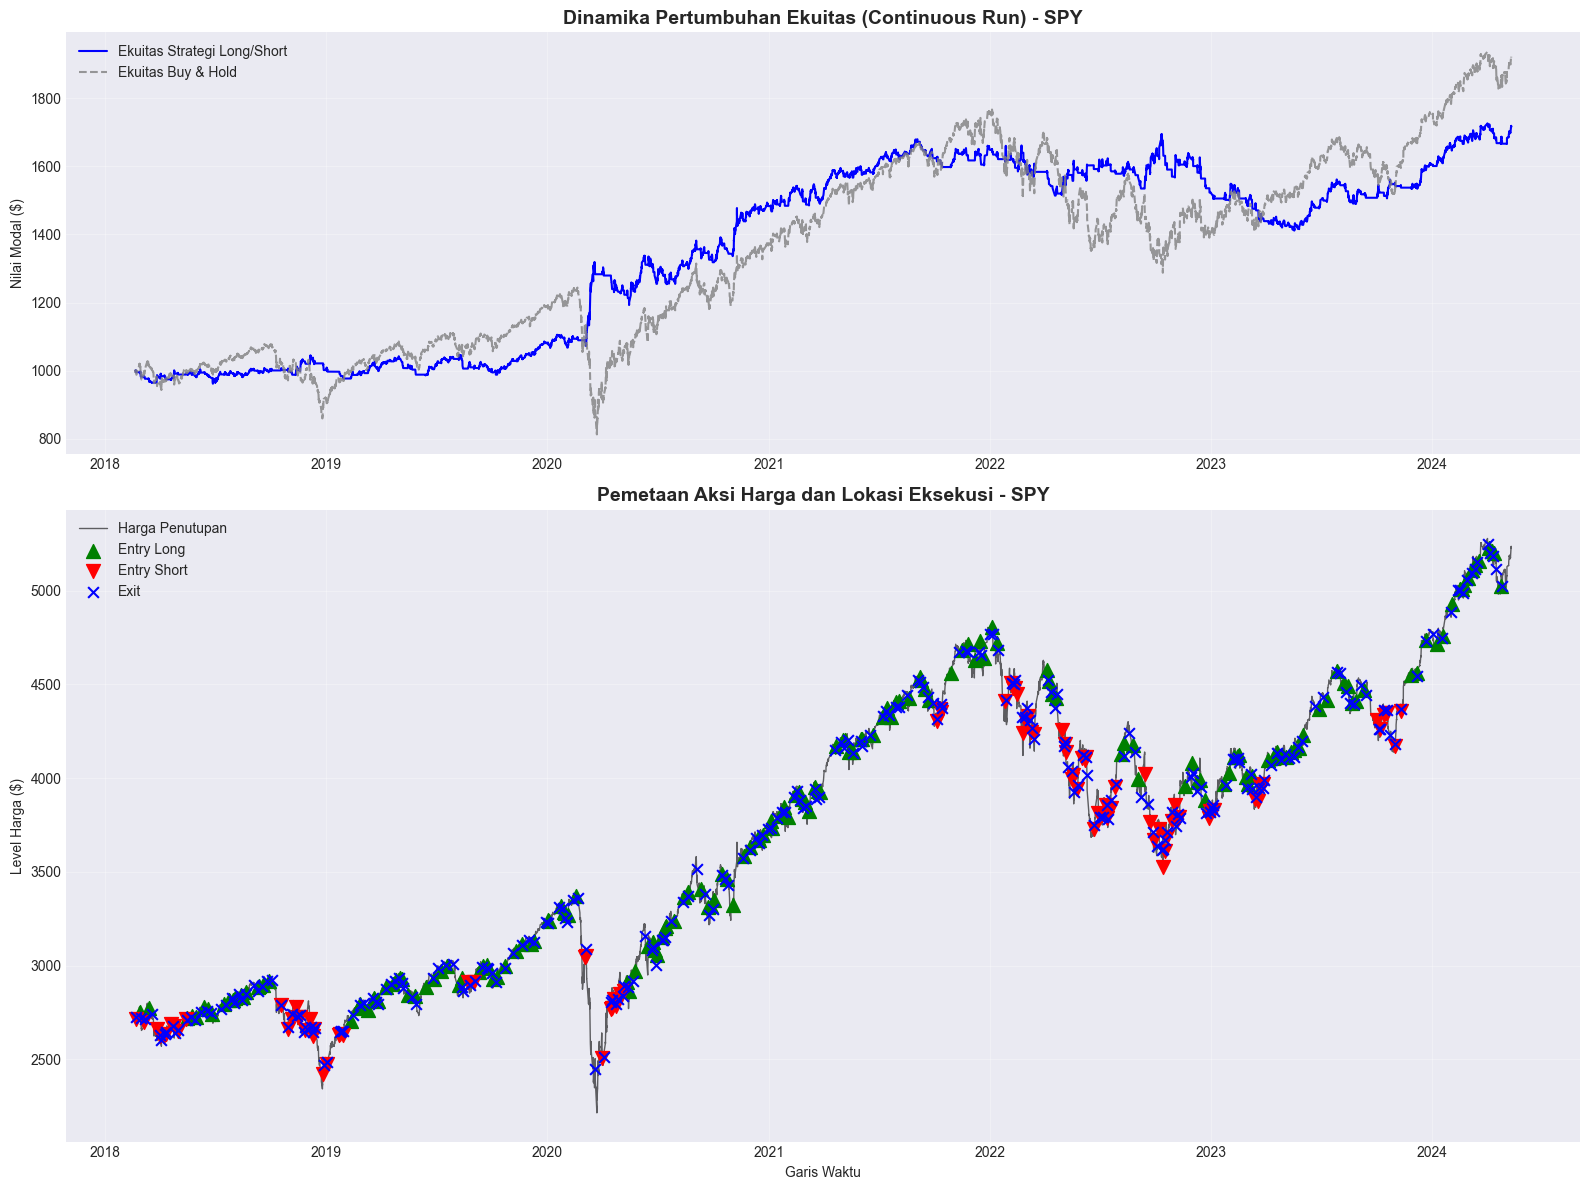

Parameter QQQ: {'ema_macro_fast': 20, 'ema_macro_slow': 50, 'ema_micro': 32, 'atr_period': 7, 'atr_mult_long': 5.0, 'atr_mult_short': 2.0, 'cooldown_bars': 6, 'enable_short': True}
HASIL EVALUASI FASE PASAR - [NASDAQ 100 (QQQ)]
Periode simulasi : 2018-02-20 09:00 s.d. 2024-05-10 16:00 (12,761 bar 1H)

[TABEL 1: PERFORMA STRATEGI TRADING]
          Fase Pasar Return(%) CAGR(%) Max DD(%) Sharpe Sortino Win Rate(%) R/R Ratio Time(%) Trades
Keseluruhan Berjalan    181.23   17.71    -15.80   1.32    1.92       43.35      2.27   52.31    263
             Bullish    114.41   18.51    -13.77   1.65    2.63       46.30      2.19   61.67    162
             Bearish     31.16   15.84    -14.24   1.67    4.12       38.61      2.35   29.53    101
            Sideways      0.00    0.00      0.00   0.00    0.00        0.00      0.00    0.00      0

[TABEL 2: PERFORMA BUY & HOLD (B&H)]
          Fase Pasar Return(%) CAGR(%) Max DD(%) Sharpe Sortino Win Rate(%) R/R Ratio Time(%) Trades
Keseluruhan Berj

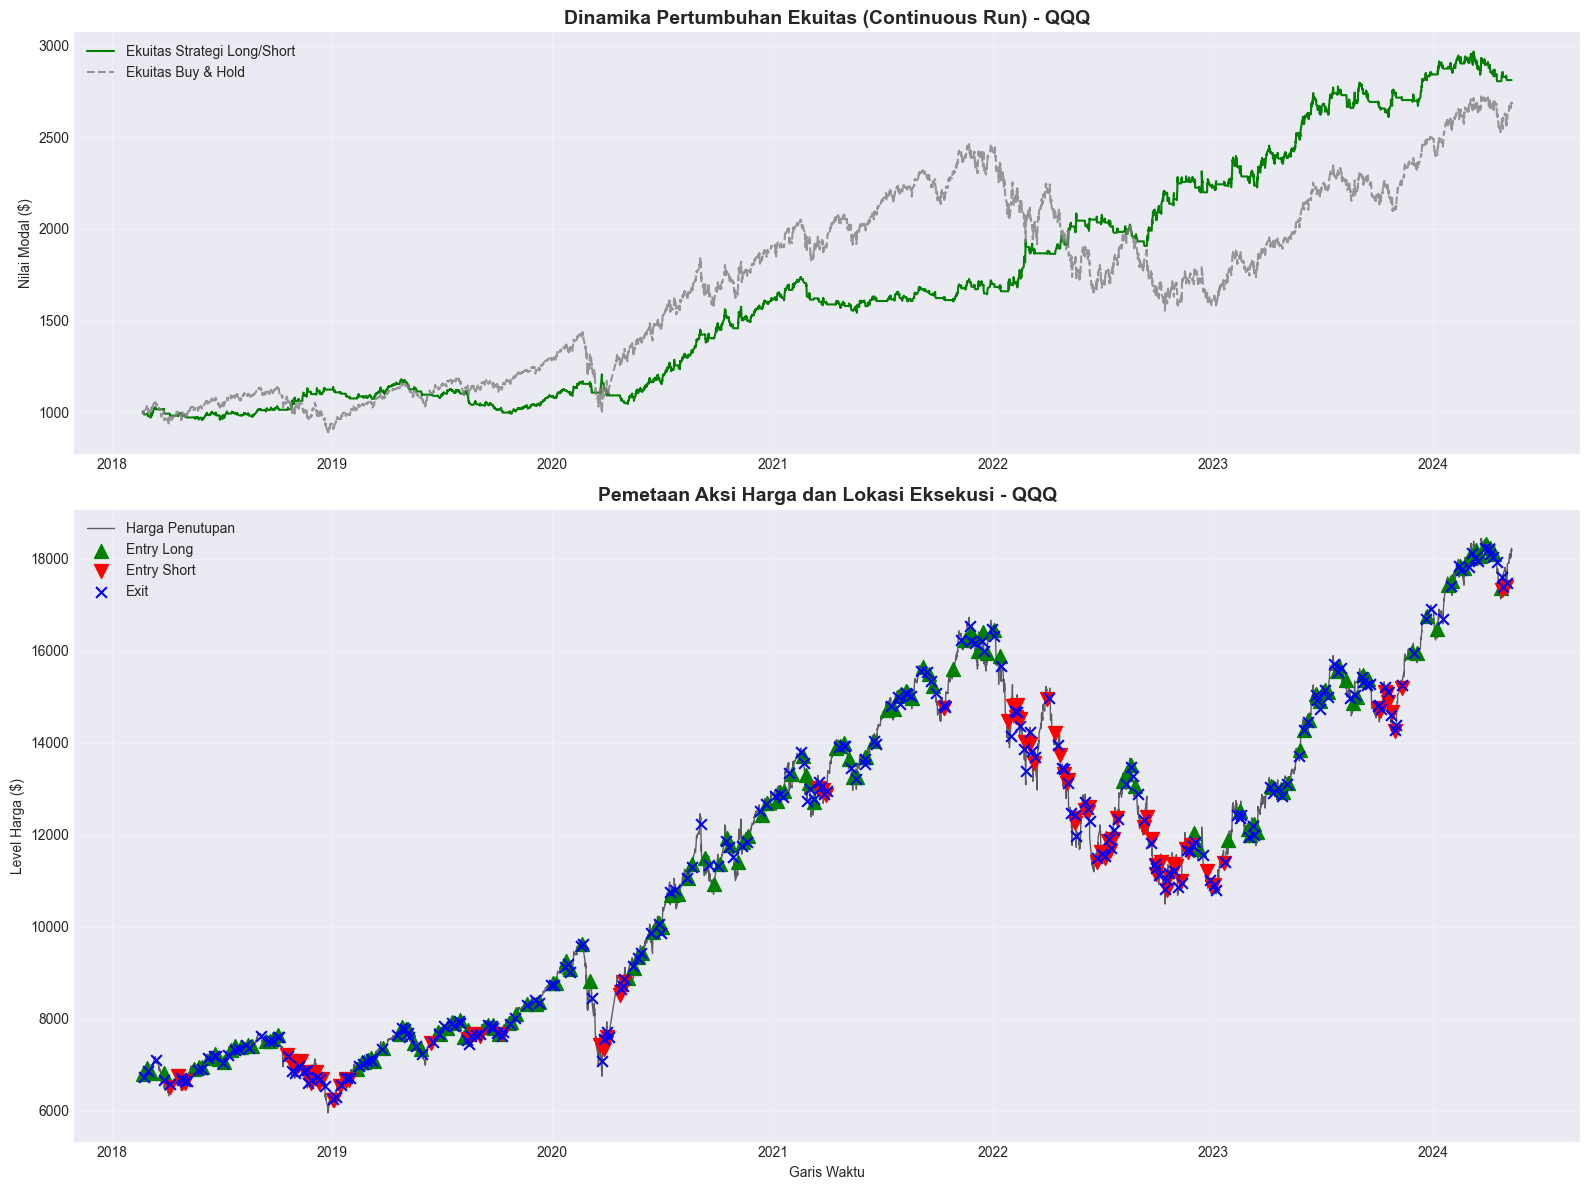

Parameter DJI: {'ema_macro_fast': 20, 'ema_macro_slow': 50, 'ema_micro': 32, 'atr_period': 7, 'atr_mult_long': 5.0, 'atr_mult_short': 2.0, 'cooldown_bars': 6, 'enable_short': True}
HASIL EVALUASI FASE PASAR - [DOW JONES (DJI)]
Periode simulasi : 2018-02-20 09:00 s.d. 2024-05-10 16:00 (12,842 bar 1H)

[TABEL 1: PERFORMA STRATEGI TRADING]
          Fase Pasar Return(%) CAGR(%) Max DD(%) Sharpe Sortino Win Rate(%) R/R Ratio Time(%) Trades
Keseluruhan Berjalan     16.05    2.36    -15.41   0.30    0.43       38.78      1.81   48.38    263
             Bullish      9.64    2.19    -12.08   0.35    0.59       43.31      1.51   58.17    157
             Bearish      5.84    2.71    -18.28   0.47    1.04       32.08      2.38   28.79    106
            Sideways      0.00    0.00      0.00   0.00    0.00        0.00      0.00    0.00      0

[TABEL 2: PERFORMA BUY & HOLD (B&H)]
          Fase Pasar Return(%) CAGR(%) Max DD(%) Sharpe Sortino Win Rate(%) R/R Ratio Time(%) Trades
Keseluruhan Berja

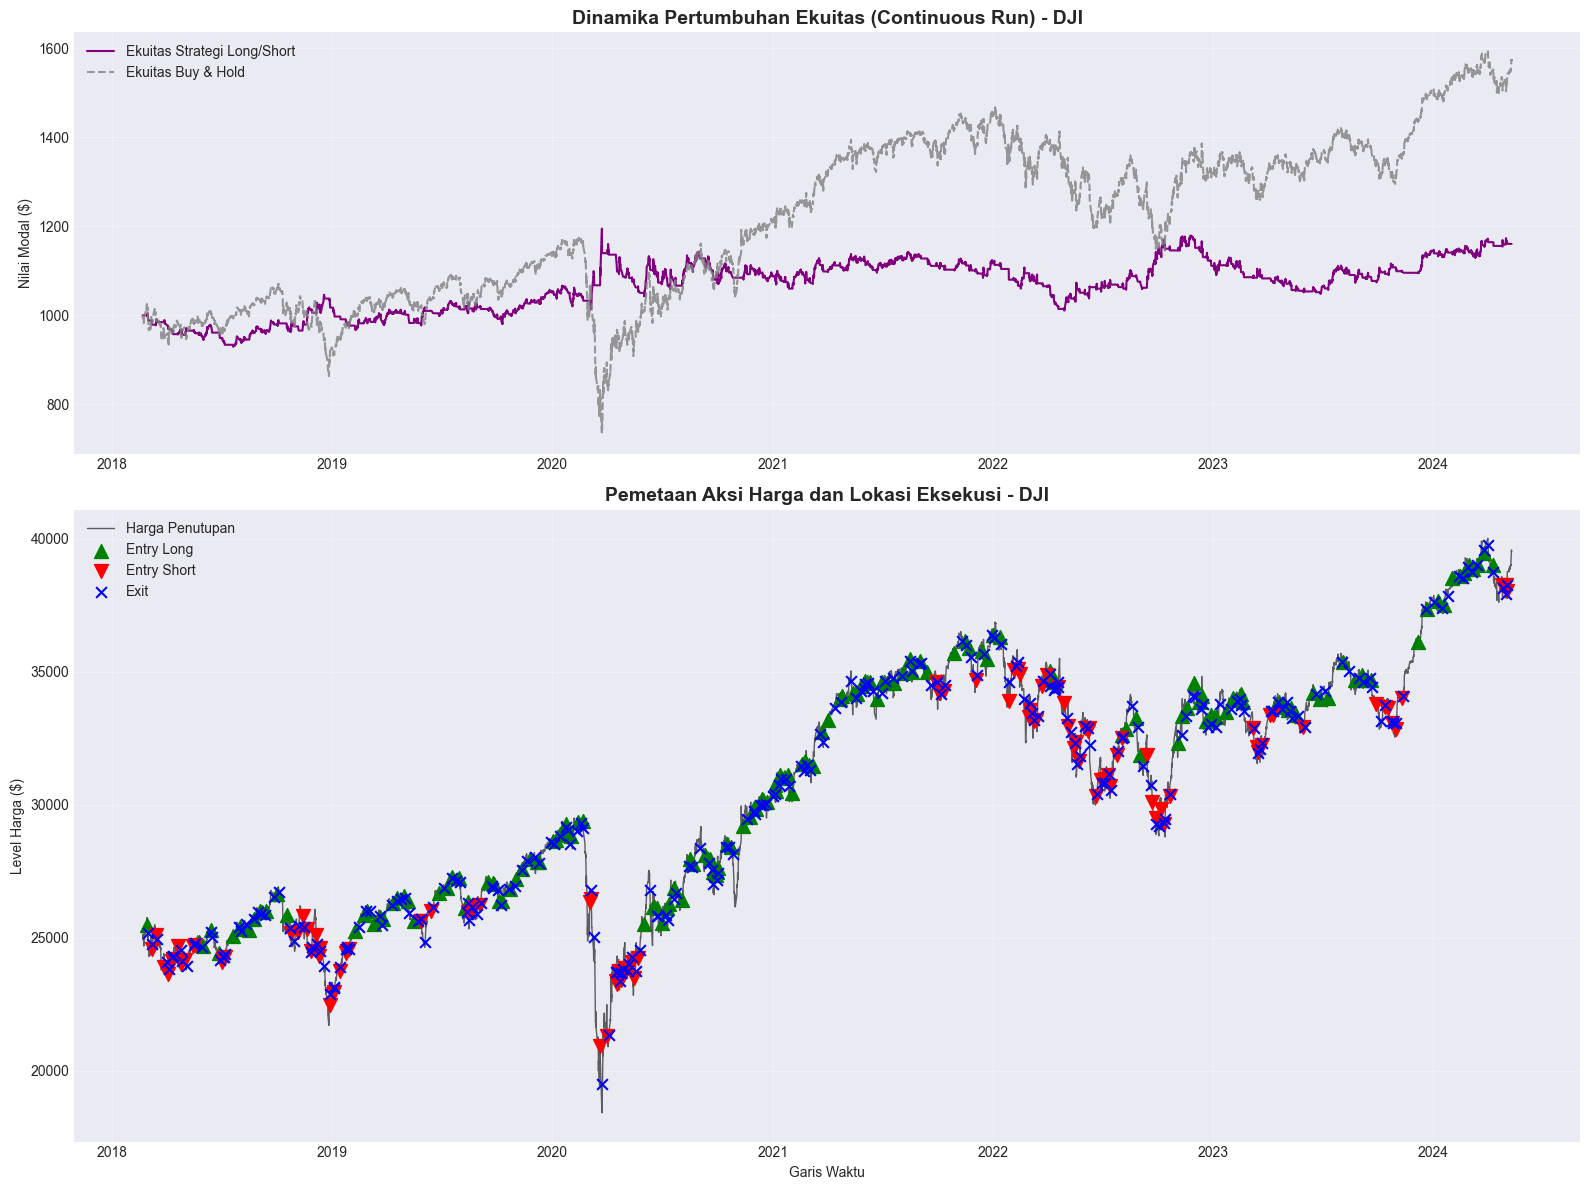

Parameter AAPL: {'ema_macro_fast': 20, 'ema_macro_slow': 50, 'ema_micro': 32, 'atr_period': 7, 'atr_mult_long': 5.0, 'atr_mult_short': 2.0, 'cooldown_bars': 6, 'enable_short': True}
HASIL EVALUASI FASE PASAR - [APPLE INC. (AAPL)]
Periode simulasi : 2018-02-20 09:00 s.d. 2024-05-10 16:00 (11,872 bar 1H)

[TABEL 1: PERFORMA STRATEGI TRADING]
          Fase Pasar Return(%) CAGR(%) Max DD(%) Sharpe Sortino Win Rate(%) R/R Ratio Time(%) Trades
Keseluruhan Berjalan    289.88   25.99    -19.75   1.21    1.72       43.33      3.26   81.84     60
             Bullish    275.86   39.42    -19.75   1.85    2.74       64.71      4.43   89.48     17
             Bearish      3.73    1.95    -20.11   0.18    0.30       34.88      1.64   66.00     43
            Sideways      0.00    0.00      0.00   0.00    0.00        0.00      0.00    0.00      0

[TABEL 2: PERFORMA BUY & HOLD (B&H)]
          Fase Pasar Return(%) CAGR(%) Max DD(%) Sharpe Sortino Win Rate(%) R/R Ratio Time(%) Trades
Keseluruhan Be

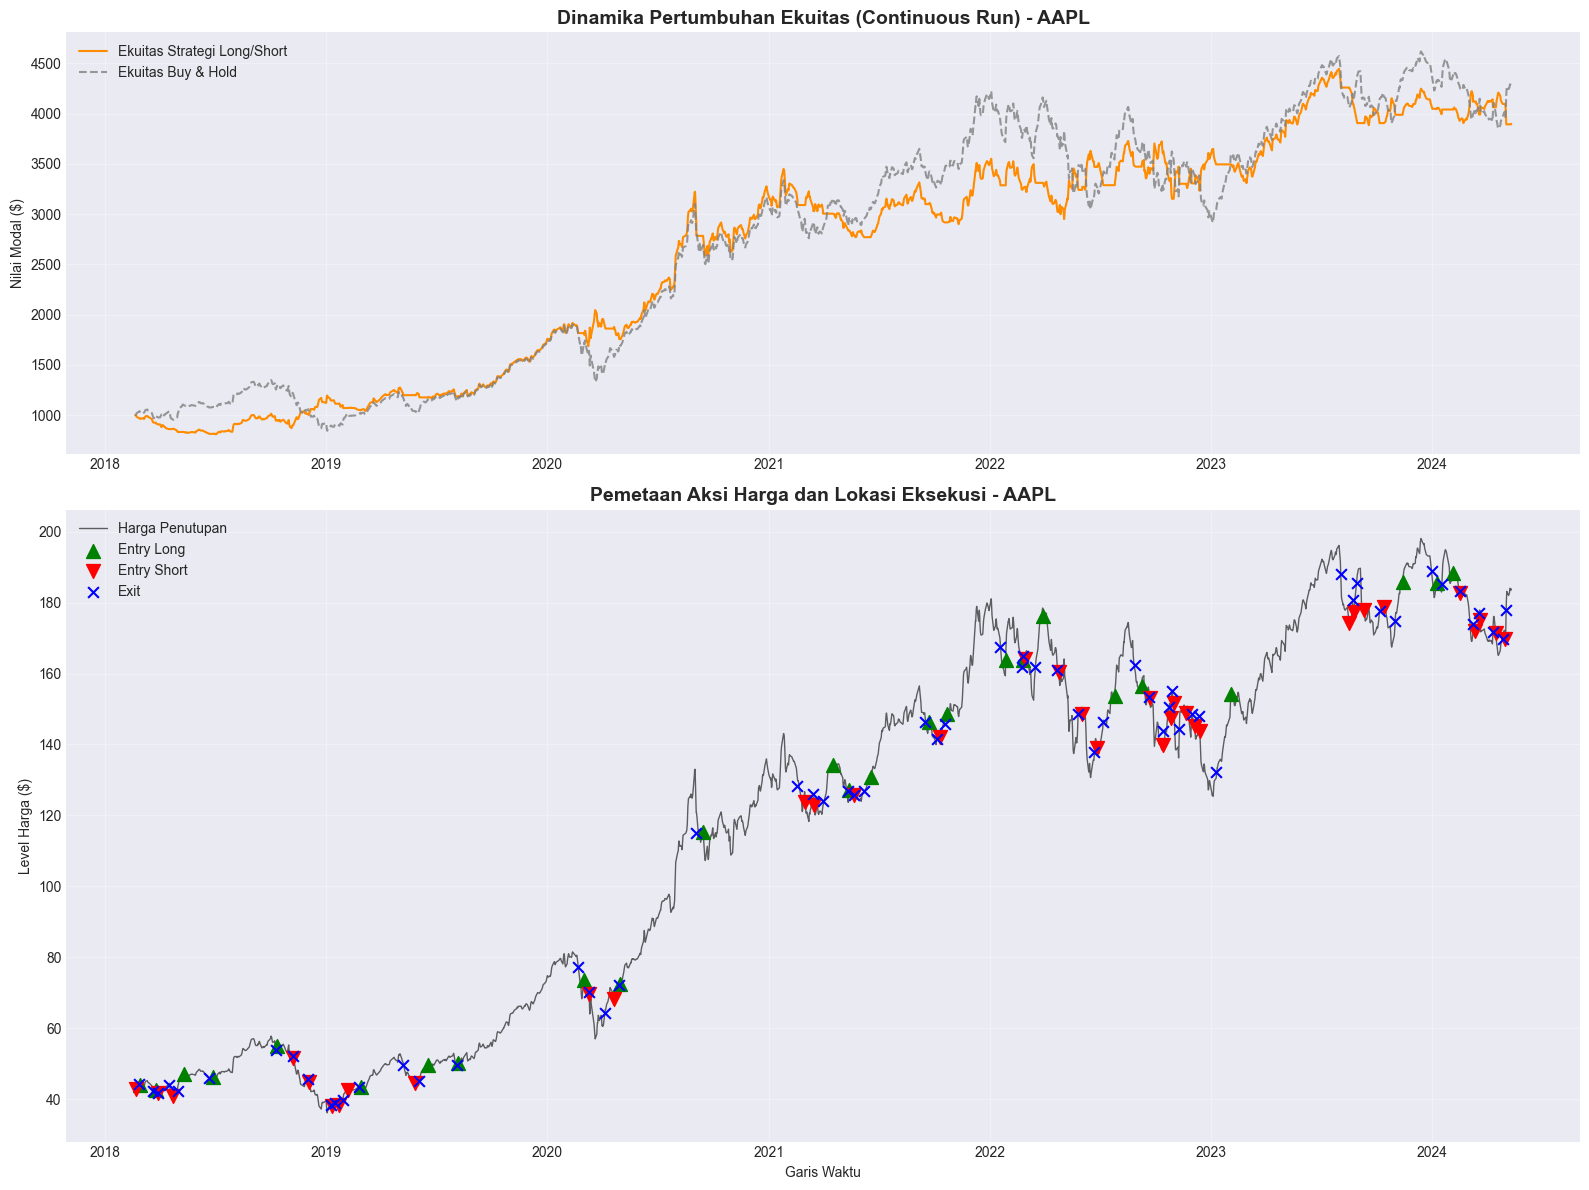

In [316]:
# =============================================================================
# BLOK 6: EKSEKUSI & EVALUASI SELURUH INSTRUMEN (PARAMETER UNIVERSAL)
# Seluruh instrumen menggunakan GLOBAL_PARAMS tanpa override lokal.
# =============================================================================
list_instrumen = list(CONFIG['instruments'])

if 'DATA' in locals():
    for symbol in list_instrumen:
        current_params = GLOBAL_PARAMS.copy()
        print(f"Parameter {symbol}: {current_params}")
        eksekusi_instrumen(symbol, params=current_params)
